In [ ]:
# 그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
# 프로그램 관련 import
import pandas as pd
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier # 분류 관련
import numpy as np

In [112]:
# 도미
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [113]:
# 데이터 전처리
total_length = bream_length+smelt_length
total_weight = bream_weight+smelt_weight

In [114]:
data = [[l,w] for l, w in zip(total_length,total_weight)]
# data = np.column_stack((total_length,total_weight)) # 이 방법을 써도 됨. 행렬에 숫자 연산이 편함(덧셈) data+2하면 반영됨
# data2 = np.array(data)
data

[[25.4, 242.0],
 [26.3, 290.0],
 [26.5, 340.0],
 [29.0, 363.0],
 [29.0, 430.0],
 [29.7, 450.0],
 [29.7, 500.0],
 [30.0, 390.0],
 [30.0, 450.0],
 [30.7, 500.0],
 [31.0, 475.0],
 [31.0, 500.0],
 [31.5, 500.0],
 [32.0, 340.0],
 [32.0, 600.0],
 [32.0, 600.0],
 [33.0, 700.0],
 [33.0, 700.0],
 [33.5, 610.0],
 [33.5, 650.0],
 [34.0, 575.0],
 [34.0, 685.0],
 [34.5, 620.0],
 [35.0, 680.0],
 [35.0, 700.0],
 [35.0, 725.0],
 [35.0, 720.0],
 [36.0, 714.0],
 [36.0, 850.0],
 [37.0, 1000.0],
 [38.5, 920.0],
 [38.5, 955.0],
 [39.5, 925.0],
 [41.0, 975.0],
 [41.0, 950.0],
 [9.8, 6.7],
 [10.5, 7.5],
 [10.6, 7.0],
 [11.0, 9.7],
 [11.2, 9.8],
 [11.3, 8.7],
 [11.8, 10.0],
 [11.8, 9.9],
 [12.0, 9.8],
 [12.2, 12.2],
 [12.4, 13.4],
 [13.0, 12.2],
 [14.3, 19.7],
 [15.0, 19.9]]

In [115]:
# 정규화 작업
# 표준점수 = (특성값-산술평균)/표준편차
mean = np.mean(data,axis=0) # 행기준 산술평균
std = np.std(data,axis=0) # 행기준 표준편차
train_scaled = (data-mean)/std

In [ ]:
# 정규화 작업 -> 이렇게 하면 단한번에 바뀜
ss = StandardScaler() # 정규화 선언
ss.fit(data) # 정규화 학습
train_scaled = ss.transform(data) # 정규화 변환
train_data, test_data, train_label, test_label=\
train_test_split(data,label)
train_scaled

array([[-0.16326134, -0.62350364],
       [-0.07448421, -0.47571019],
       [-0.05475596, -0.32175867],
       [ 0.19184717, -0.25094097],
       [ 0.19184717, -0.04464594],
       [ 0.26089605,  0.01693467],
       [ 0.26089605,  0.17088618],
       [ 0.29048842, -0.16780715],
       [ 0.29048842,  0.01693467],
       [ 0.3595373 ,  0.17088618],
       [ 0.38912967,  0.09391043],
       [ 0.38912967,  0.17088618],
       [ 0.4384503 ,  0.17088618],
       [ 0.48777093, -0.32175867],
       [ 0.48777093,  0.47878922],
       [ 0.48777093,  0.47878922],
       [ 0.58641218,  0.78669225],
       [ 0.58641218,  0.78669225],
       [ 0.6357328 ,  0.50957952],
       [ 0.6357328 ,  0.63274074],
       [ 0.68505343,  0.40181346],
       [ 0.68505343,  0.7405068 ],
       [ 0.73437406,  0.54036983],
       [ 0.78369468,  0.72511165],
       [ 0.78369468,  0.78669225],
       [ 0.78369468,  0.86366801],
       [ 0.78369468,  0.84827286],
       [ 0.88233593,  0.82979868],
       [ 0.88233593,

In [116]:
train_scaled

array([[-0.16326134, -0.62350364],
       [-0.07448421, -0.47571019],
       [-0.05475596, -0.32175867],
       [ 0.19184717, -0.25094097],
       [ 0.19184717, -0.04464594],
       [ 0.26089605,  0.01693467],
       [ 0.26089605,  0.17088618],
       [ 0.29048842, -0.16780715],
       [ 0.29048842,  0.01693467],
       [ 0.3595373 ,  0.17088618],
       [ 0.38912967,  0.09391043],
       [ 0.38912967,  0.17088618],
       [ 0.4384503 ,  0.17088618],
       [ 0.48777093, -0.32175867],
       [ 0.48777093,  0.47878922],
       [ 0.48777093,  0.47878922],
       [ 0.58641218,  0.78669225],
       [ 0.58641218,  0.78669225],
       [ 0.6357328 ,  0.50957952],
       [ 0.6357328 ,  0.63274074],
       [ 0.68505343,  0.40181346],
       [ 0.68505343,  0.7405068 ],
       [ 0.73437406,  0.54036983],
       [ 0.78369468,  0.72511165],
       [ 0.78369468,  0.78669225],
       [ 0.78369468,  0.86366801],
       [ 0.78369468,  0.84827286],
       [ 0.88233593,  0.82979868],
       [ 0.88233593,

In [117]:
# label = [1]*35 + [0]*14
label = ['도미']*35 + ['빙어']*14 # 이렇게 처리해도 됨

In [118]:
# 학습데이터, 테스트데이터 분리
train_data, test_data, train_label,test_label = \
train_test_split(data,label)

In [119]:
# 데이터 학습, 데이터 예측, 정확도
clf = KNeighborsClassifier()
clf.fit(train_data, train_label)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[<U2](2,)","['도미','빙어']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [120]:
result = clf.predict(test_data)
# score = clf.score(test_data,test_label)
score = metrics.accuracy_score(result,test_label)
print("정확도:", score)

정확도: 1.0


In [121]:
## input 받아 도미인지, 빙어인지 분류하시오.
# 길이, 무게를 받아서 적용해야 함

In [98]:
input1 = input("생선의 길이와 무게를 입력하시오.(예: 25, 120)")
# input1 = '25,120'
input1 = input1.split(',')
input1
input2 = list(map(float,input1))
input2
new_input = (input2-mean)/std

In [122]:
# result = clf.predict([input2])
result2 = clf.predict([new_input])
print("예측생선:",result2)

예측생선: ['빙어']


In [123]:
distance, indexes = clf.kneighbors([new_input]) # 선택어종으로 판단하게 된 데이터가 어떤 것인지 알려줌

In [124]:
indexes # 도출되는 숫자들을 보고 판단했다는 것임

array([[30, 34, 35,  7, 22]])

In [ ]:
# [머신러닝 확인 사항]
# 1.데이터 전처리 - null값 등
# 2.정규화 작업
# 3.학습데이터, 테스트데이터 분리
# 4.데이터학습,데이터예측,정확도
# 5.산점도 그래프

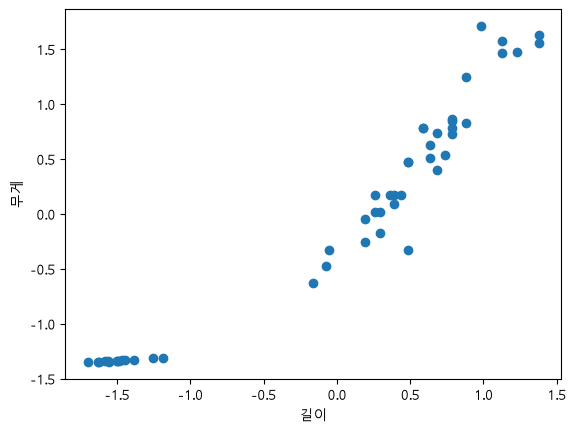

In [125]:
# 그래프 출력
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

TypeError: list indices must be integers or slices, not tuple

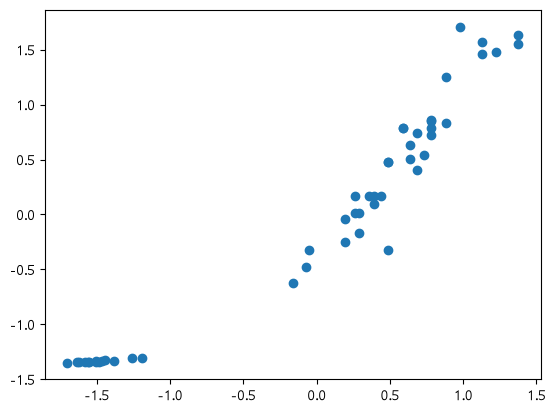

In [130]:
# 그래프 출력
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(train_data[indexes,0],train_data[indexes,1], marker='D')
plt.scatter(new_input[0],new_input[1], marker='^')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()